# Microdata choice training: attribute-level OLS treatment effects (`Figure 2a–2e`)

Horizontal bars compare `Off-the-shelf` against pooled choice training (`Drones + Electricity`) relative to black vertical `Human (OLS)` ticks across all five evaluation datasets. Main-text exports: `Consumer rights — Laptops` (`fig_results_laptops_slopes.{png,pdf}`, held-out price test set) and `Vaccines` (`fig_results_vaccines_slopes.{png,pdf}`, held-out non-price test set). Web Appendix export: `Flights` (`fig_results_flights_slopes.{png,pdf}`, validation set).

In [1]:
import sys
from pathlib import Path
from IPython.display import display

PAPER_DIR = next(
    (
        p
        for p in (
            Path.cwd(),
            *Path.cwd().parents,
            Path.cwd() / "train-notebooks" / "beta-training" / "ms_paper_beta_loss",
            Path.cwd() / "code" / "train-notebooks" / "beta-training" / "ms_paper_beta_loss",
        )
        if (p / "microdata_analysis.py").is_file()
    ),
    None,
)
if PAPER_DIR is None:
    raise FileNotFoundError(f"Could not locate microdata_analysis.py from {Path.cwd()}")
if str(PAPER_DIR) not in sys.path:
    sys.path.insert(0, str(PAPER_DIR))

import microdata_analysis as ma

ctx = ma.load_microdata_context()
print(f"Loaded {len(ctx.regimes_by_model)} models from {ma.PAPER_RUNS_ROOT}")


Loaded 3 models from /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual


Figure 2a
Flights (validation) OLS treatment effects by attribute: off-the-shelf versus pooled choice training
Saved /home/dw/github/decision-models-finetuning/manuscript/figures/fig_results_flights_slopes.{png,pdf}
Note. Bars show each model's OLS treatment effect (β) for each Flights (Goldfarb et al., 2026) attribute level, comparing Off-the-shelf against pooled Drones + Electricity; the black vertical tick marks the human OLS slope on the same row. Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. Exact values for all four regimes are in Table A3. Flights is the validation dataset and selects each run's checkpoint (best.pt).


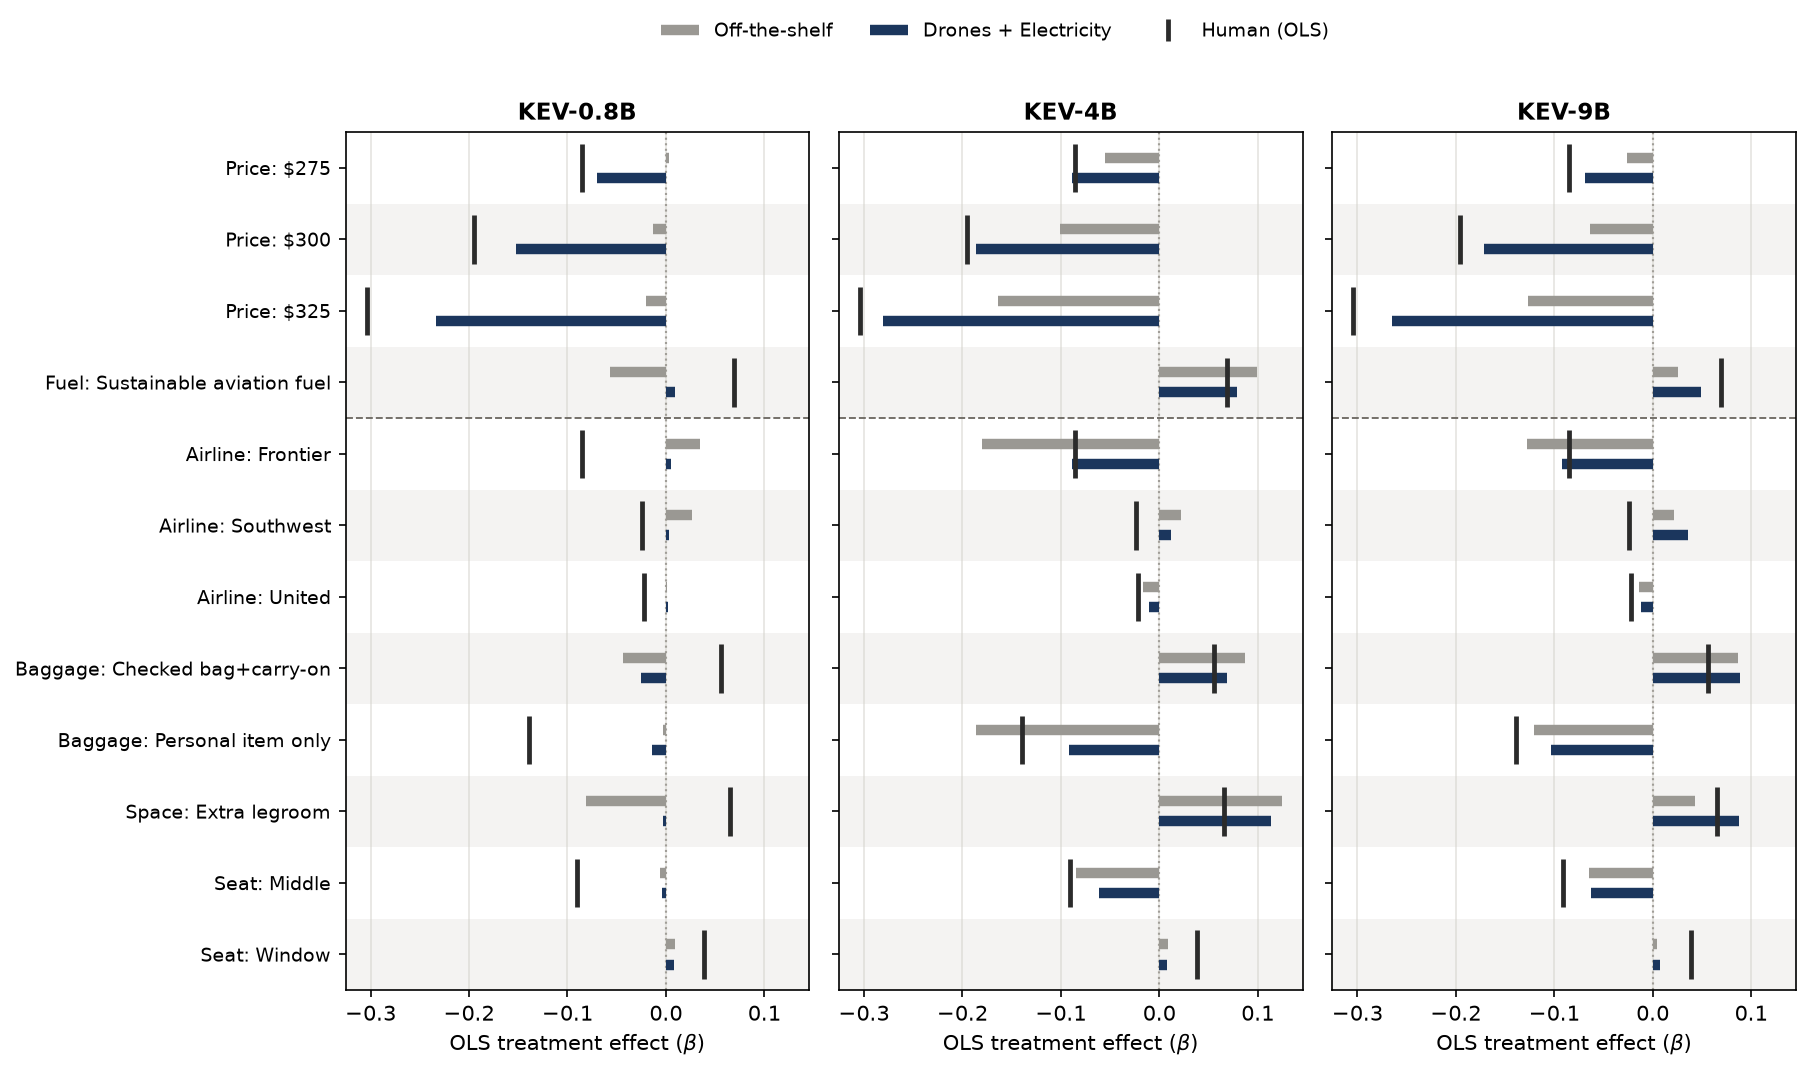

In [2]:
# Figure 2a: Flights (validation) — exports fig_results_flights_slopes.{png,pdf}
ma.print_caption(
    "Figure 2a",
    "Flights (validation) OLS treatment effects by attribute: off-the-shelf versus pooled choice training",
)
ma.plot_slope_bars(
    betas_by_model=ctx.kriner_betas_by_model,
    terms=ctx.kriner_terms,
    divider_ys=(ctx.kriner_transferred_count - 0.5,),
    left_pad=2.0,
    save_stem="fig_results_flights_slopes",
)
ma.print_note(
    "Bars show each model's OLS treatment effect (β) for each Flights (Goldfarb et al., 2026) attribute level, comparing Off-the-shelf against pooled Drones + Electricity; "
    "the black vertical tick marks the human OLS slope on the same row. "
    "Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. "
    "Exact values for all four regimes are in Table A3. Flights is the validation dataset and selects each run's checkpoint (best.pt)."
)


Figure 2b
Consumer rights — Laptops (held-out test): OLS treatment effects by attribute
Saved /home/dw/github/decision-models-finetuning/manuscript/figures/fig_results_laptops_slopes.{png,pdf}
Figure 2b
Consumer rights — Laundry machines (held-out test): OLS treatment effects by attribute


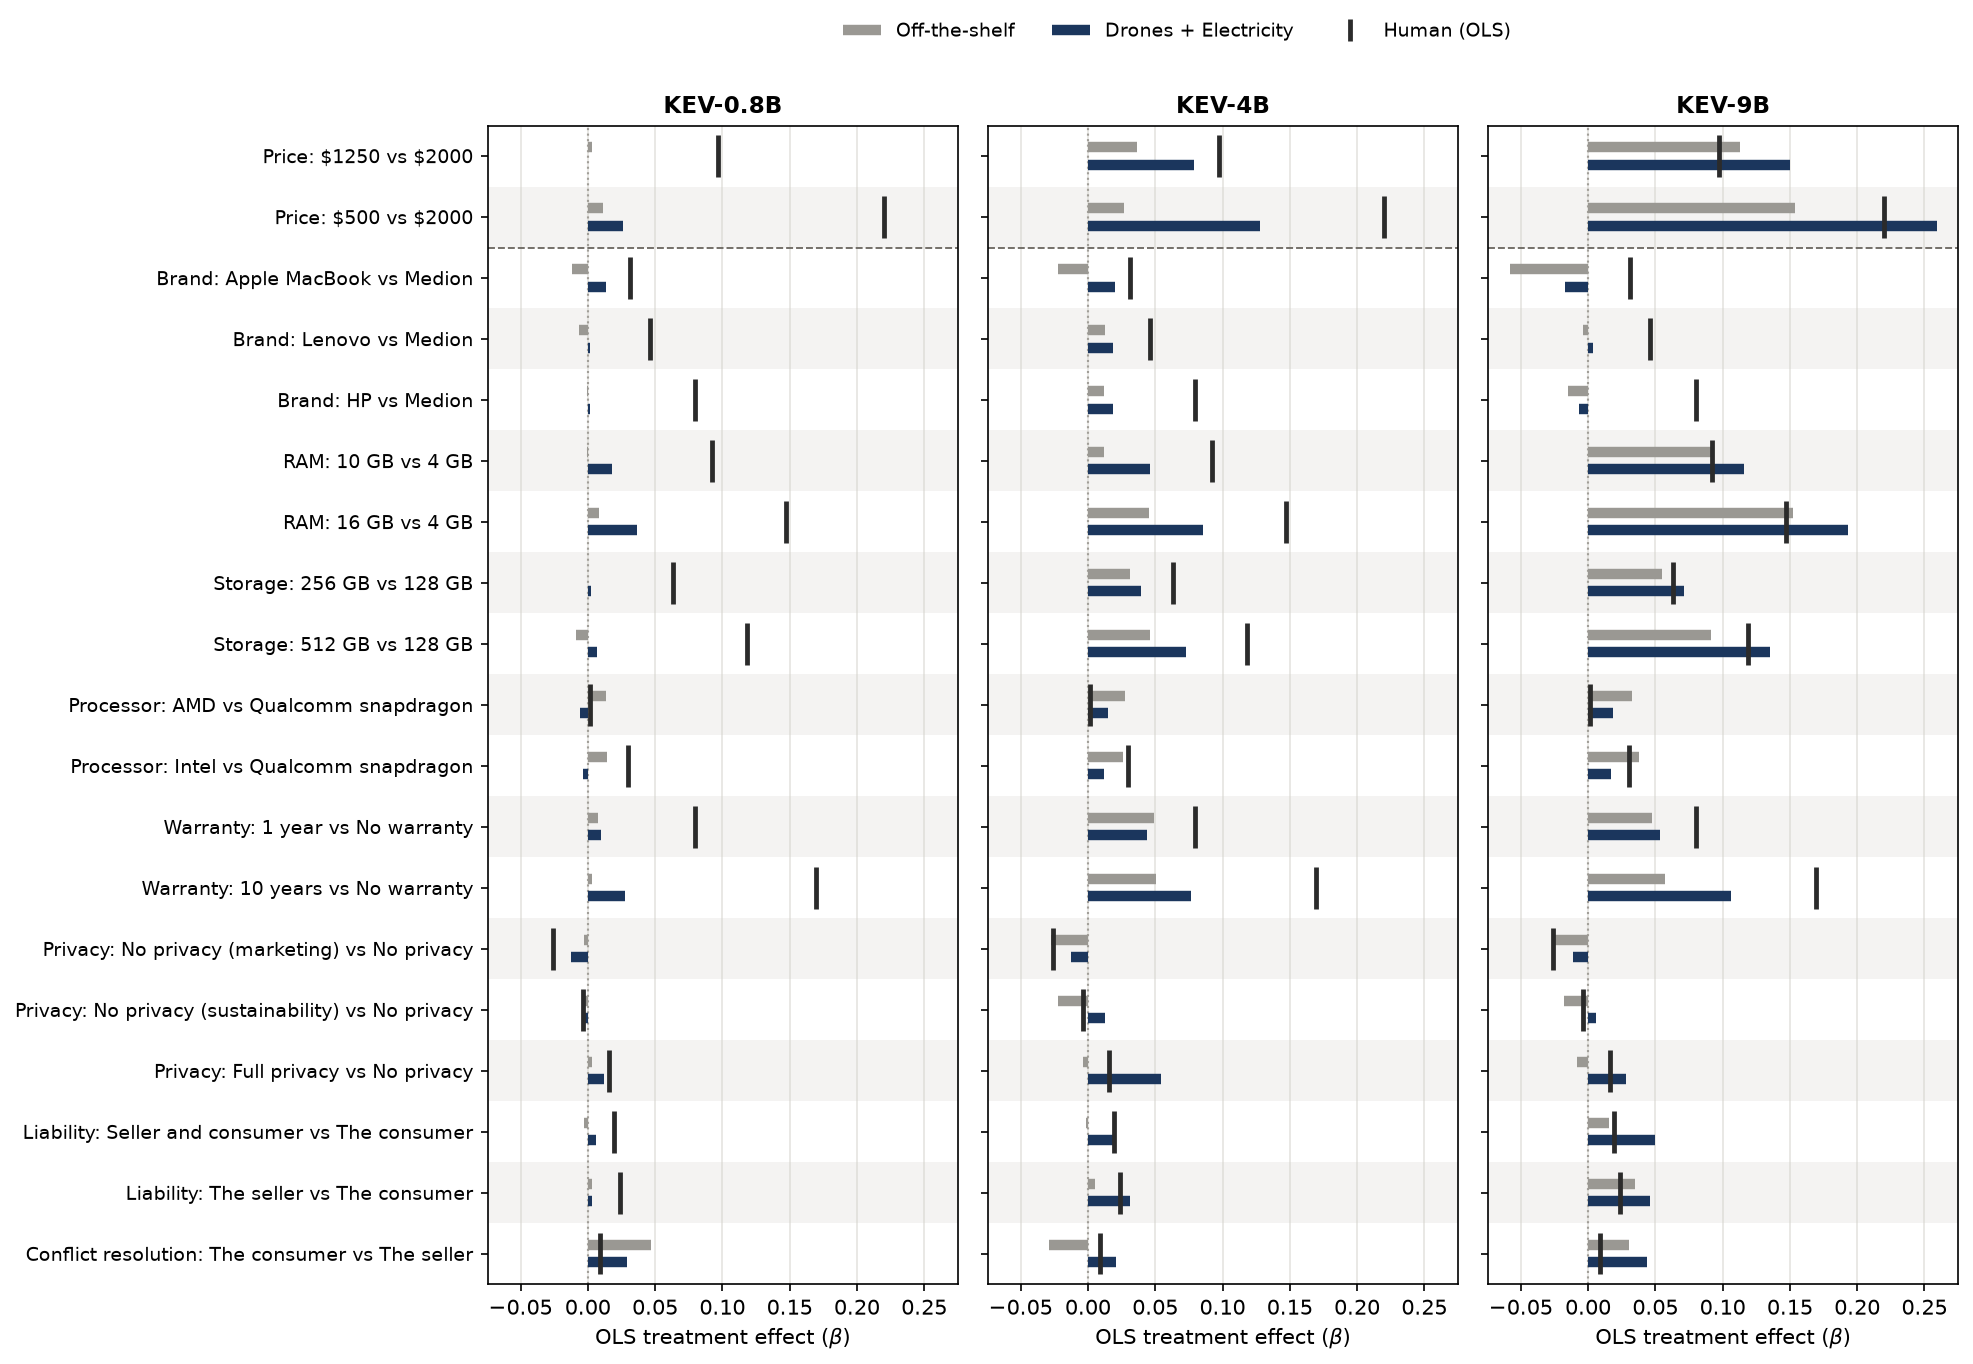

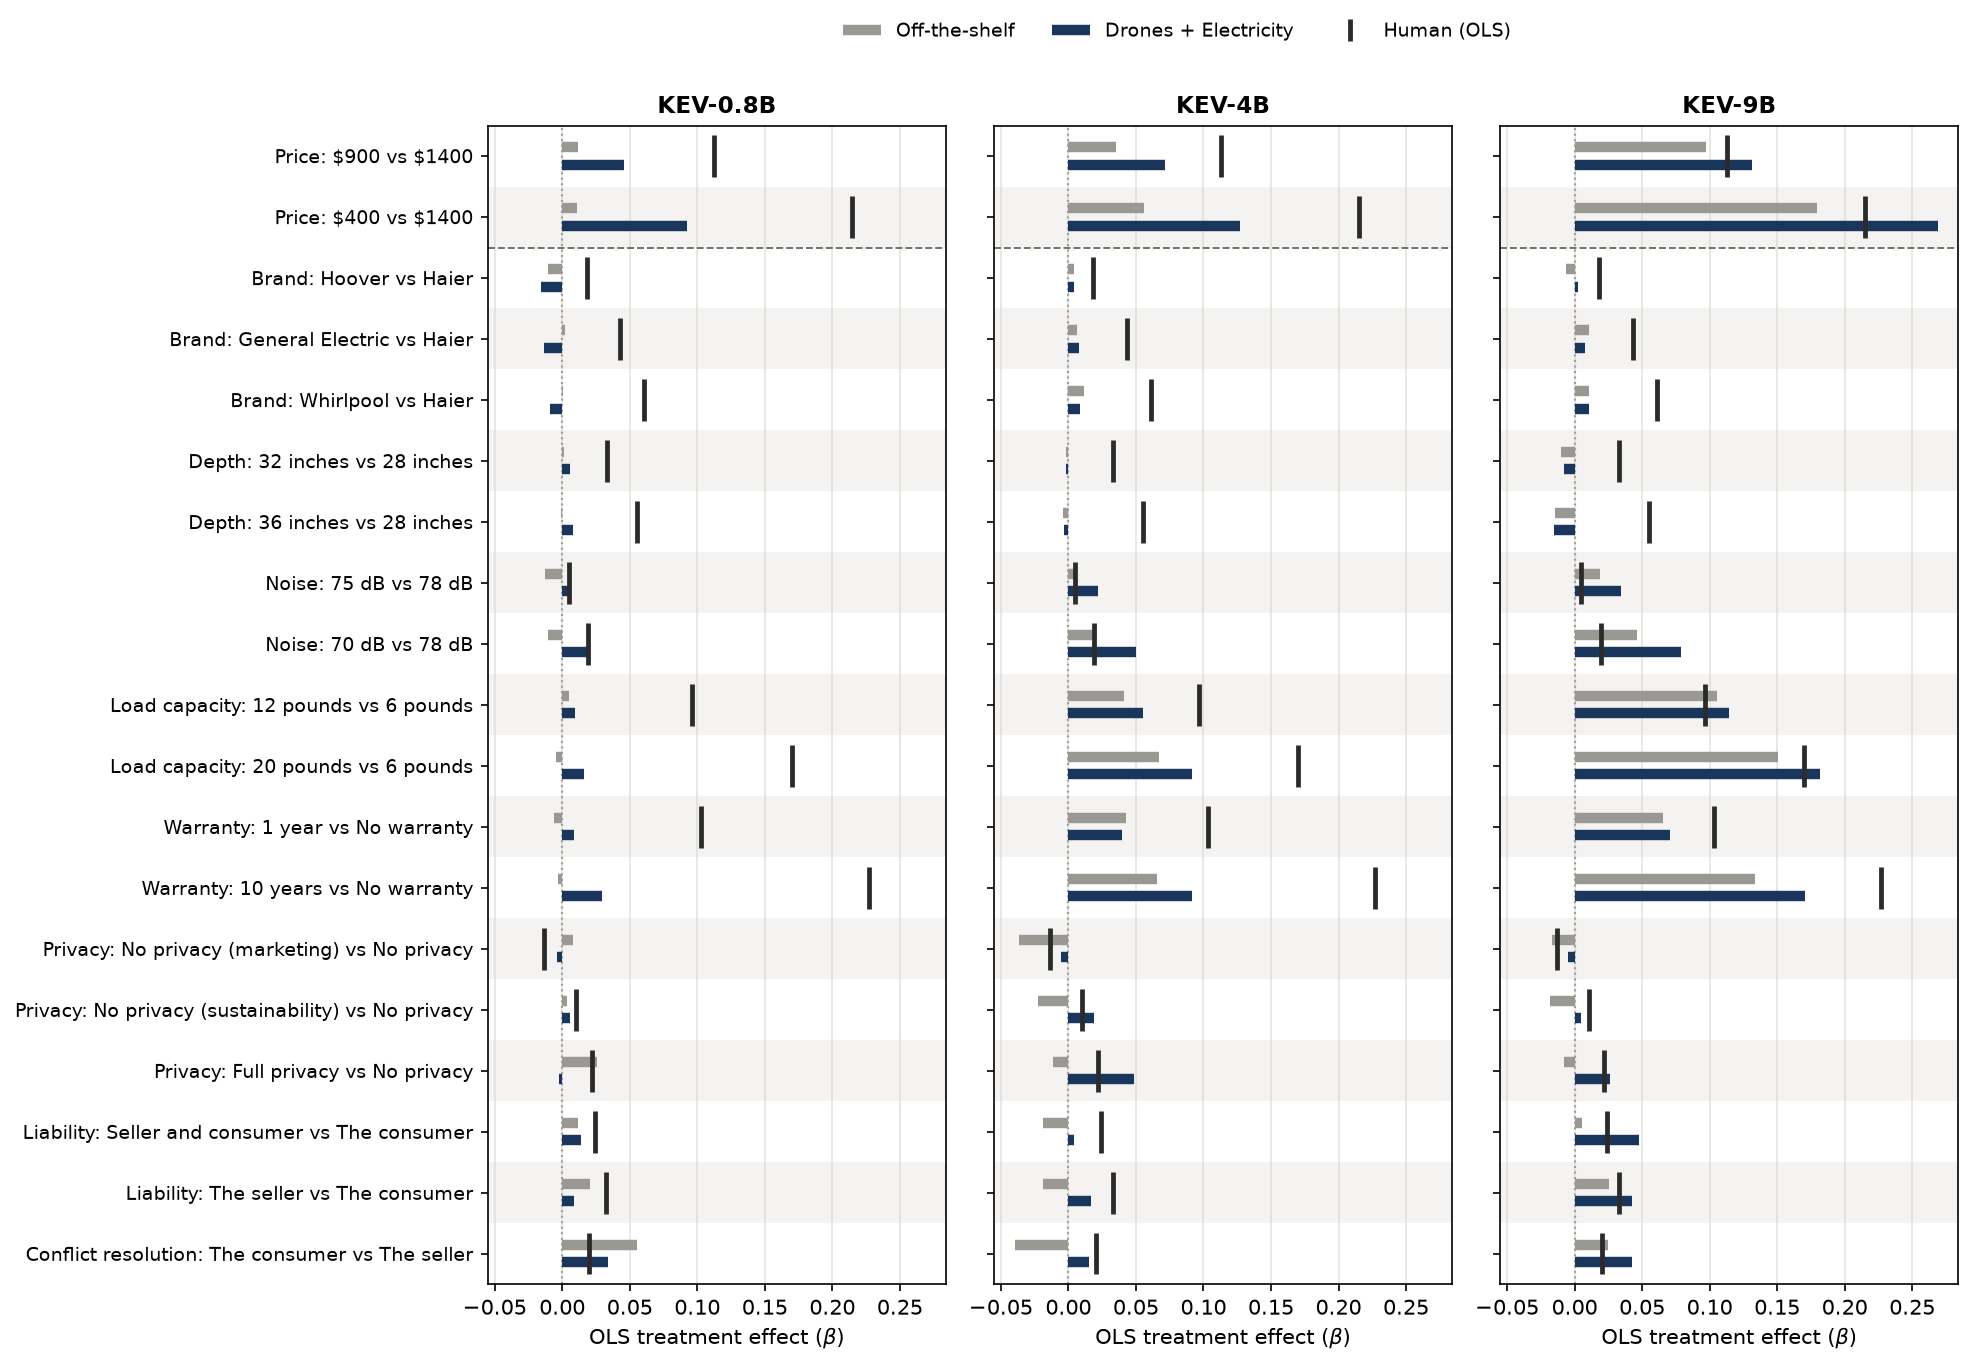

In [3]:
# Figure 2b: Consumer rights (held-out test: price study) — Laptops (19, exported) and Laundry (19)
all_k26_terms = list(ctx.kantorowicz_betas_by_model[ma.MODEL_SLUGS[0]][ma.BASE_SLUG].index)
for prefix, sub_title, stem in (
    ("Computers | ", "Consumer rights — Laptops (held-out test)", "fig_results_laptops_slopes"),
    ("Laundry | ", "Consumer rights — Laundry machines (held-out test)", None),
):
    sub_terms = [t for t in all_k26_terms if t.startswith(prefix)]
    if not sub_terms:
        raise ValueError(f"No Consumer rights terms starting with {prefix!r}")
    sub_labels = [t[len(prefix):] for t in sub_terms]
    n_price = sum(1 for lbl in sub_labels if lbl.startswith("Price:"))
    if n_price == 0:
        raise ValueError(f"No Price terms found for {prefix!r}")
    ma.print_caption("Figure 2b", f"{sub_title}: OLS treatment effects by attribute")
    ma.plot_slope_bars(
        betas_by_model=ctx.kantorowicz_betas_by_model,
        terms=sub_terms,
        display_labels=sub_labels,
        divider_ys=(n_price - 0.5,),
        left_pad=3.2,
        row_height=0.38,
        legend_x=0.60,
        save_stem=stem,
    )


Figure 2c
AI & offshoring — US (held-out test): OLS treatment effects by attribute
Figure 2c
AI & offshoring — Canada (held-out test): OLS treatment effects by attribute


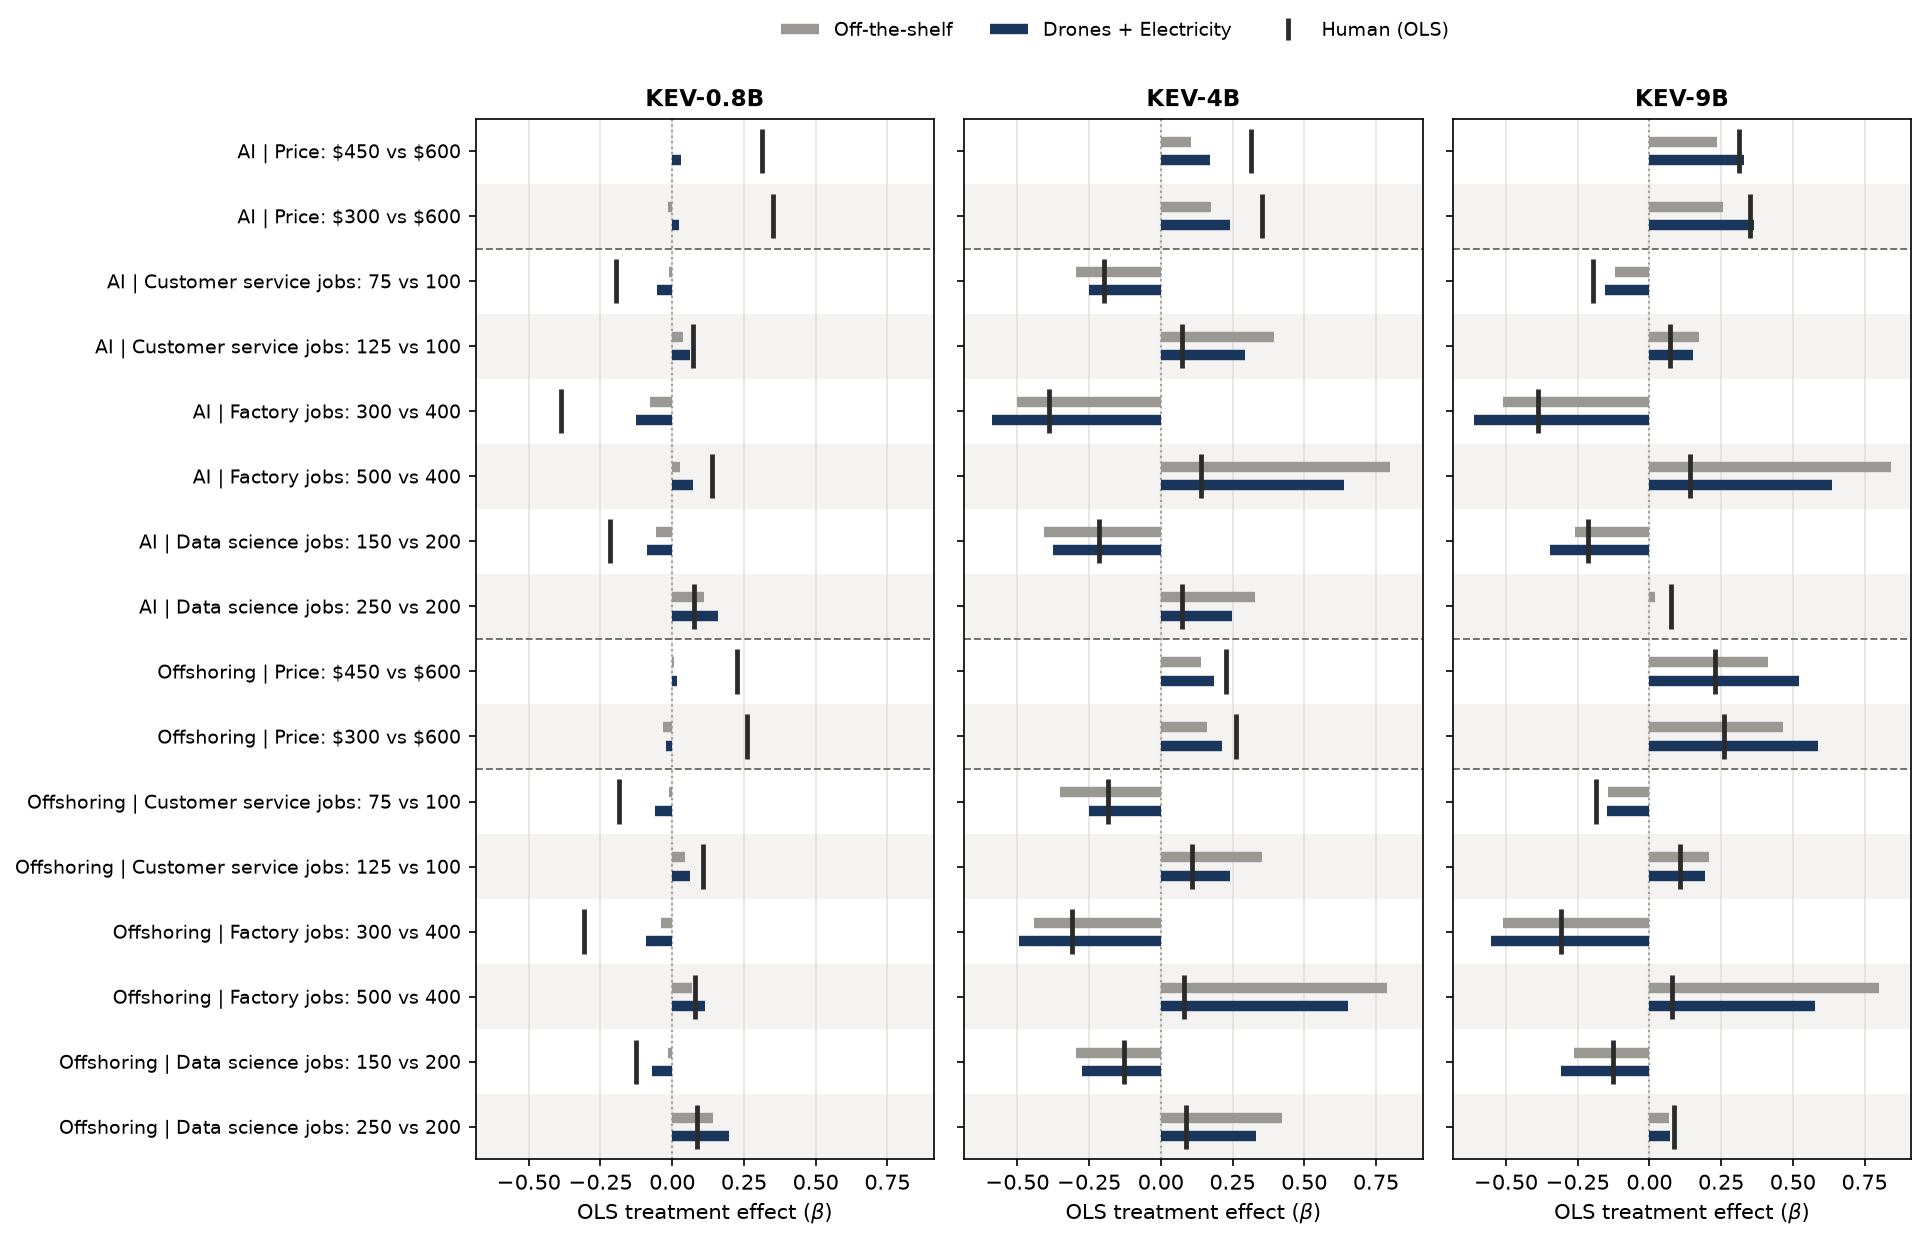

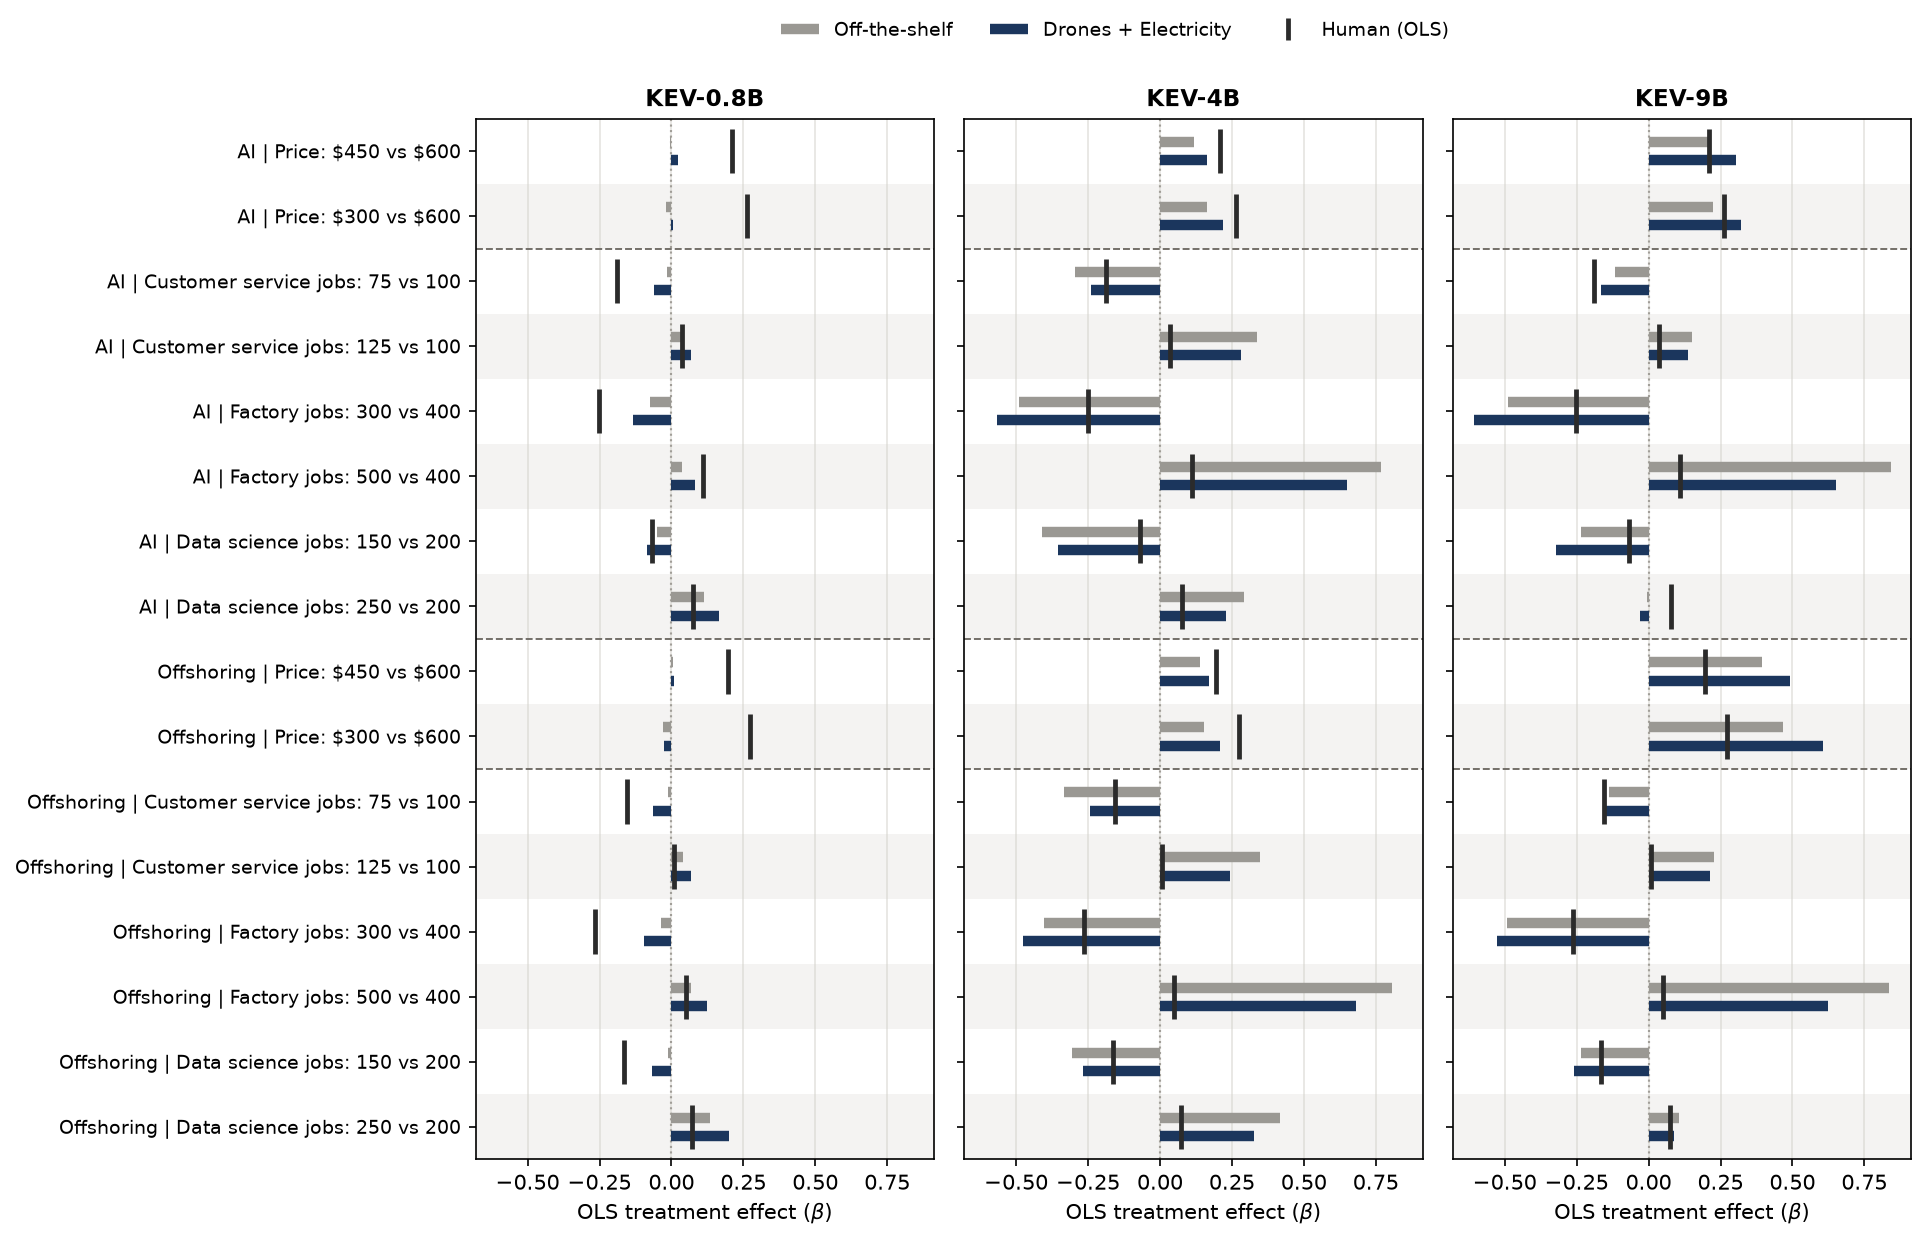

In [4]:
# Figure 2c: AI & offshoring (held-out test: price study) — US (16) and Canada (16)
all_m25_terms = list(ctx.magistro_betas_by_model[ma.MODEL_SLUGS[0]][ma.BASE_SLUG].index)
for country_prefix, sub_title in (
    ("US ", "AI & offshoring — US (held-out test)"),
    ("Canada ", "AI & offshoring — Canada (held-out test)"),
):
    sub_terms = [t for t in all_m25_terms if t.startswith(country_prefix)]
    if len(sub_terms) != 16:
        raise ValueError(f"Expected 16 terms for {country_prefix!r}, got {len(sub_terms)}")
    sub_labels = [t[len(country_prefix):] for t in sub_terms]
    ma.print_caption("Figure 2c", f"{sub_title}: OLS treatment effects by attribute")
    ma.plot_slope_bars(
        betas_by_model=ctx.magistro_betas_by_model,
        terms=sub_terms,
        display_labels=sub_labels,
        divider_ys=(1.5, 7.5, 9.5),
        left_pad=2.8,
        row_height=0.40,
        legend_x=0.58,
    )


Figure 2d
Food labels (held-out test): OLS treatment effects by treatment arm


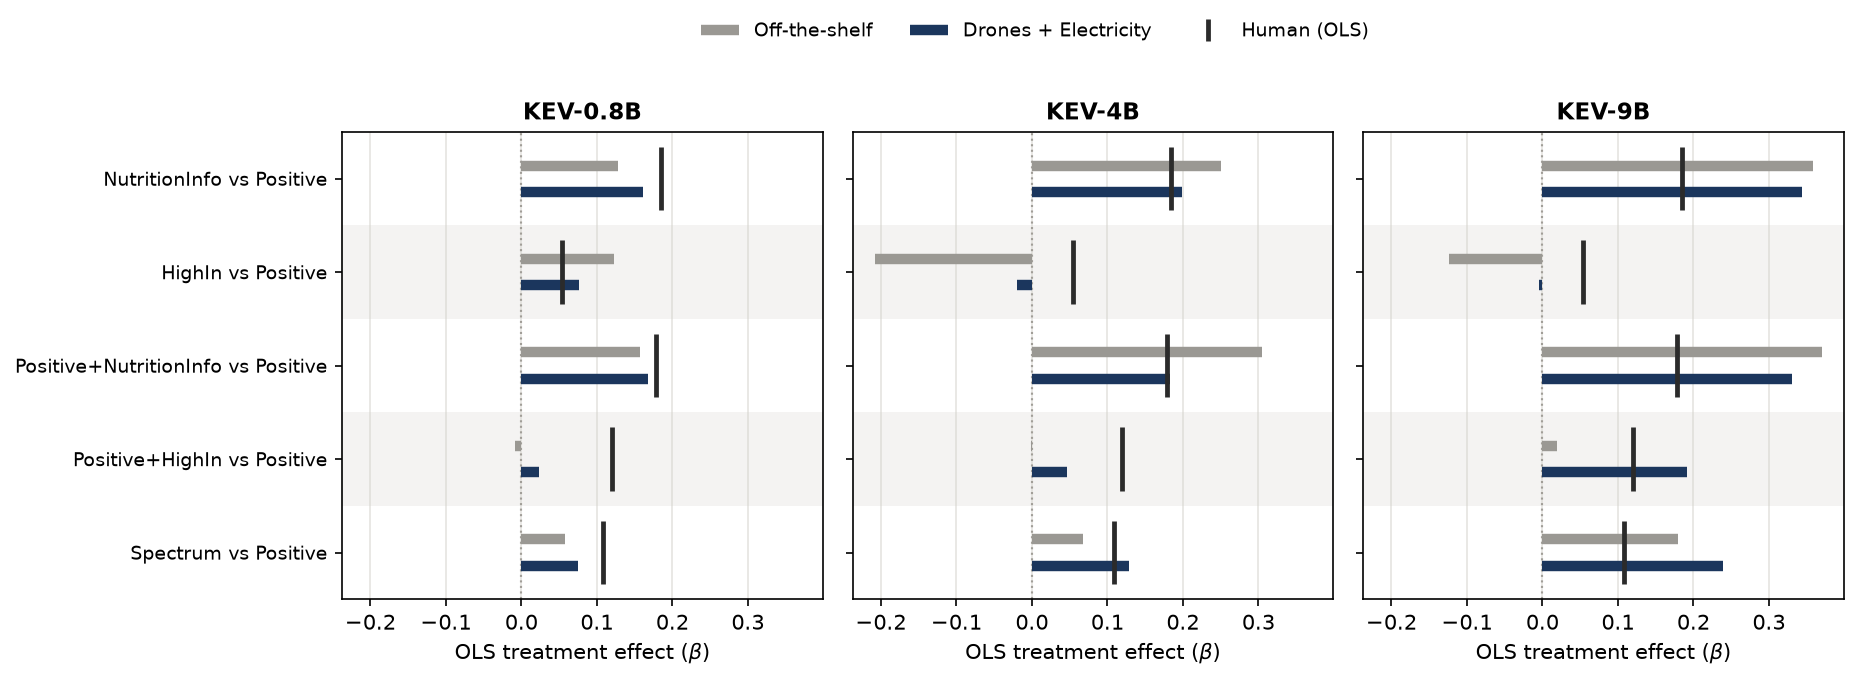

In [5]:
# Figure 2d: Food labels (held-out test: non-price study) — 5 warning-label arms
grummon_terms = list(ctx.grummon_betas_by_model[ma.MODEL_SLUGS[0]][ma.BASE_SLUG].index)
ma.print_caption("Figure 2d", "Food labels (held-out test): OLS treatment effects by treatment arm")
ma.plot_slope_bars(
    betas_by_model=ctx.grummon_betas_by_model,
    terms=grummon_terms,
    left_pad=2.4,
    row_height=0.54,
    legend_x=0.56,
)


Figure 2e
Vaccines (held-out test): OLS treatment effects by attribute
Saved /home/dw/github/decision-models-finetuning/manuscript/figures/fig_results_vaccines_slopes.{png,pdf}


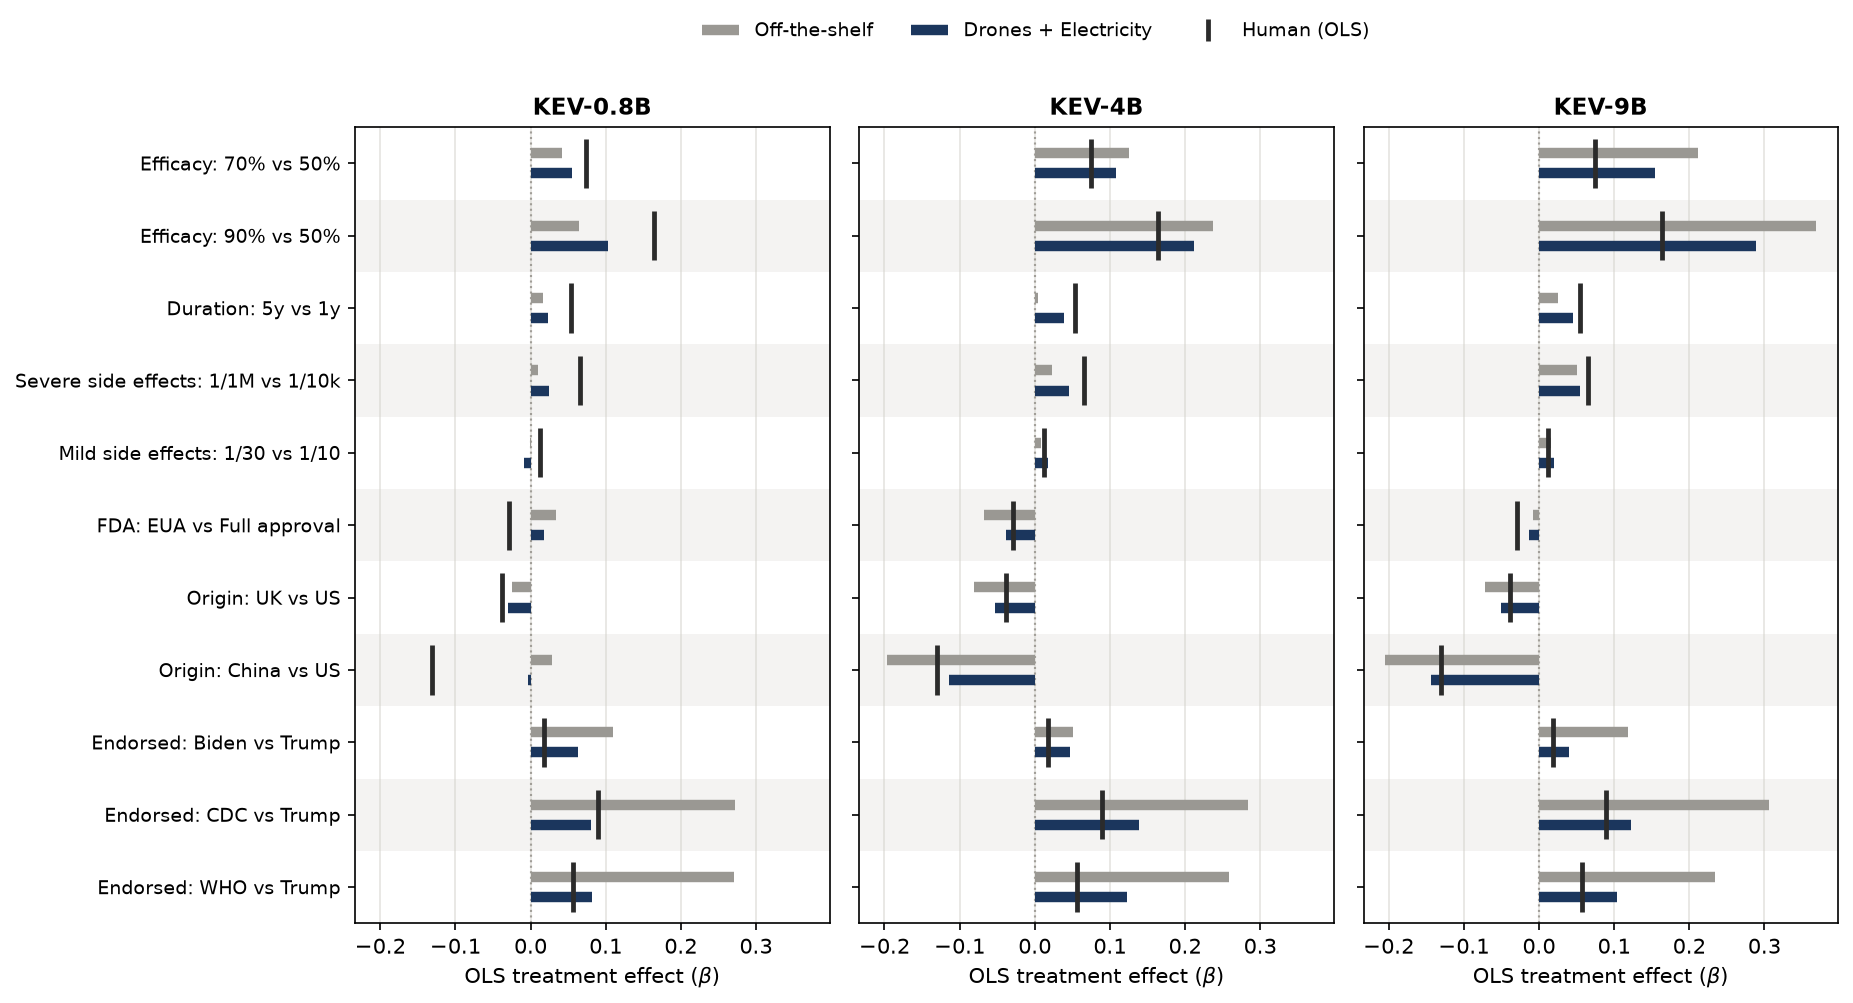

In [6]:
# Figure 2e: Vaccines (held-out test: non-price study) — 11 attribute slopes (exported)
covid_terms = list(ctx.covid_betas_by_model[ma.MODEL_SLUGS[0]][ma.BASE_SLUG].index)
ma.print_caption("Figure 2e", "Vaccines (held-out test): OLS treatment effects by attribute")
ma.plot_slope_bars(
    betas_by_model=ctx.covid_betas_by_model,
    terms=covid_terms,
    left_pad=2.3,
    row_height=0.44,
    legend_x=0.56,
    save_stem="fig_results_vaccines_slopes",
)
